# ═══════════════════════════════════════════════════════════════
# APRENDIZAJE NO SUPERVISADO — KMeans, Semi-supervisado y Activo
# ═══════════════════════════════════════════════════════════════

In [27]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

from sklearn.cluster import KMeans, MiniBatchKMeans
from sklearn.linear_model import LogisticRegression
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             silhouette_score, confusion_matrix,
                             classification_report)

SEED = 42
np.random.seed(SEED)

In [28]:
def generar_dataset(dim=2, n_centros=None, pts_rango=(100, 600),
                    std_rango=(0.4, 1.2), factor_sep=3.5, semilla=None):
    """Genera clusters gaussianos con parámetros aleatorios."""
    rng = np.random.default_rng(semilla)
    if n_centros is None:
        n_centros = int(rng.integers(1, 21))

    stds   = rng.uniform(*std_rango, size=n_centros)
    conteos = rng.integers(pts_rango[0], pts_rango[1]+1, size=n_centros)
    lado = 2 * factor_sep * 2 * std_rango[1] * n_centros ** (1/dim)

    centros, intentos = [], 0
    while len(centros) < n_centros:
        cand = rng.uniform(-lado/2, lado/2, size=dim)
        i = len(centros)
        if all(np.linalg.norm(cand - c) >= factor_sep*(stds[i]+stds[j])
               for j, c in enumerate(centros)):
            centros.append(cand); intentos = 0
        else:
            intentos += 1
            if intentos > 500:
                lado *= 1.2; intentos = 0

    centros = np.array(centros)
    X = np.vstack([c + rng.normal(size=(m, dim))*s
                   for c, s, m in zip(centros, stds, conteos)])
    y = np.repeat(np.arange(n_centros), conteos)
    orden = rng.permutation(len(X))
    return X[orden], y[orden], centros, stds, conteos

In [29]:
def _ax(fig, pos, dim):
    return fig.add_subplot(*pos, projection="3d") if dim==3 else fig.add_subplot(*pos)

def dibujar(ax, X, etiquetas=None, centros=None, titulo="", s=6):
    cmap = plt.get_cmap("tab20")
    colores = "lightgray" if etiquetas is None else [cmap(int(l)%20) for l in etiquetas]
    ax.scatter(*X.T, c=colores, s=s, alpha=0.6)
    if centros is not None:
        ax.scatter(*centros.T, c="black", marker="X", s=70,
                   edgecolors="white", linewidths=1.0, zorder=10)
    ax.set_title(titulo, fontsize=10)

def graficar_dataset(X, centros, dim):
    fig = plt.figure(figsize=(8,6))
    dibujar(_ax(fig,(1,1,1),dim), X, None, centros,
            f"Dataset ({len(X)} puntos, {len(centros)} centroides reales)")
    plt.show()

def graficar_proceso(X, k, dim, semilla=0, pasos=(1,2,3,5)):
    from sklearn.cluster import kmeans_plusplus
    init, _ = kmeans_plusplus(X, k, random_state=semilla)
    fig = plt.figure(figsize=(16,9))
    dibujar(_ax(fig,(2,3,1),dim), X, None, init, "0) Centroides iniciales (k-means++)")
    for n, it in enumerate(pasos, start=2):
        m = KMeans(n_clusters=k, init=init, n_init=1, max_iter=it,
                   algorithm="lloyd").fit(X)
        dibujar(_ax(fig,(2,3,n),dim), X, m.labels_, m.cluster_centers_,
                f"Tras {it} iteración(es)")
    m = KMeans(n_clusters=k, init=init, n_init=1, algorithm="lloyd").fit(X)
    dibujar(_ax(fig,(2,3,6),dim), X, m.labels_, m.cluster_centers_,
            f"Convergió en {m.n_iter_} iteraciones")
    plt.tight_layout(); plt.show()

def graficar_final(X, modelo, vecinos, conteos, dim):
    fig = plt.figure(figsize=(11,8))
    ax = _ax(fig,(1,1,1),dim)
    dibujar(ax, X, modelo.labels_, modelo.cluster_centers_,
            f"KMeans final (k={modelo.n_clusters})")
    for j, idx in vecinos.items():
        ax.scatter(*X[idx].T, c="red", edgecolors="black", s=28, zorder=11)
    plt.show()

In [30]:
def experimento(dim=2, n_centros=None, semilla=None):
    X, y, centros, stds, conteos = generar_dataset(dim, n_centros, semilla=semilla)
    k = len(centros)
    print(f"Centroides: {k} | puntos: {len(X)} | dim: {dim}")
    print("Puntos por centroide (real):", conteos.tolist())
    print("Std por centroide:", np.round(stds,2).tolist())

    graficar_dataset(X, centros, dim)
    graficar_proceso(X, k, dim, semilla=semilla or 0)

    modelo = KMeans(n_clusters=k, n_init=10, random_state=semilla or 0).fit(X)
    dist = modelo.transform(X)
    vecinos = {j: np.argsort(dist[:,j])[:5] for j in range(k)}

    print("\nError centroides hallados vs reales:")
    for j in range(k):
        real = centros[np.argmin(np.linalg.norm(modelo.cluster_centers_[j]-centros, axis=1))]
        print(f"  cluster {j}: {np.linalg.norm(modelo.cluster_centers_[j]-real):.3f}")

    tabla = pd.DataFrame({
        "cluster": range(k),
        "n_puntos": np.bincount(modelo.labels_, minlength=k),
        "centroide": [modelo.cluster_centers_[j].round(2).tolist() for j in range(k)],
        "idx_5_cercanos": [vecinos[j].tolist() for j in range(k)],
    })
    display(tabla)
    graficar_final(X, modelo, vecinos,
                   np.bincount(modelo.labels_, minlength=k), dim)
    return X, y, centros, modelo

Centroides: 1 | puntos: 512 | dim: 2
Puntos por centroide (real): [512]
Std por centroide: [0.91]


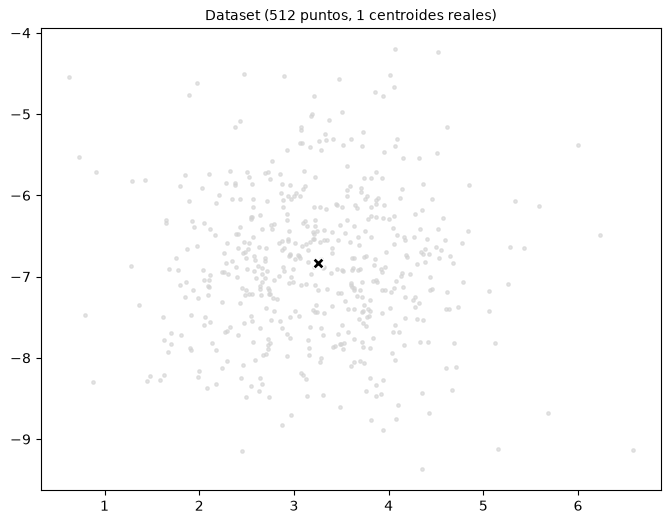

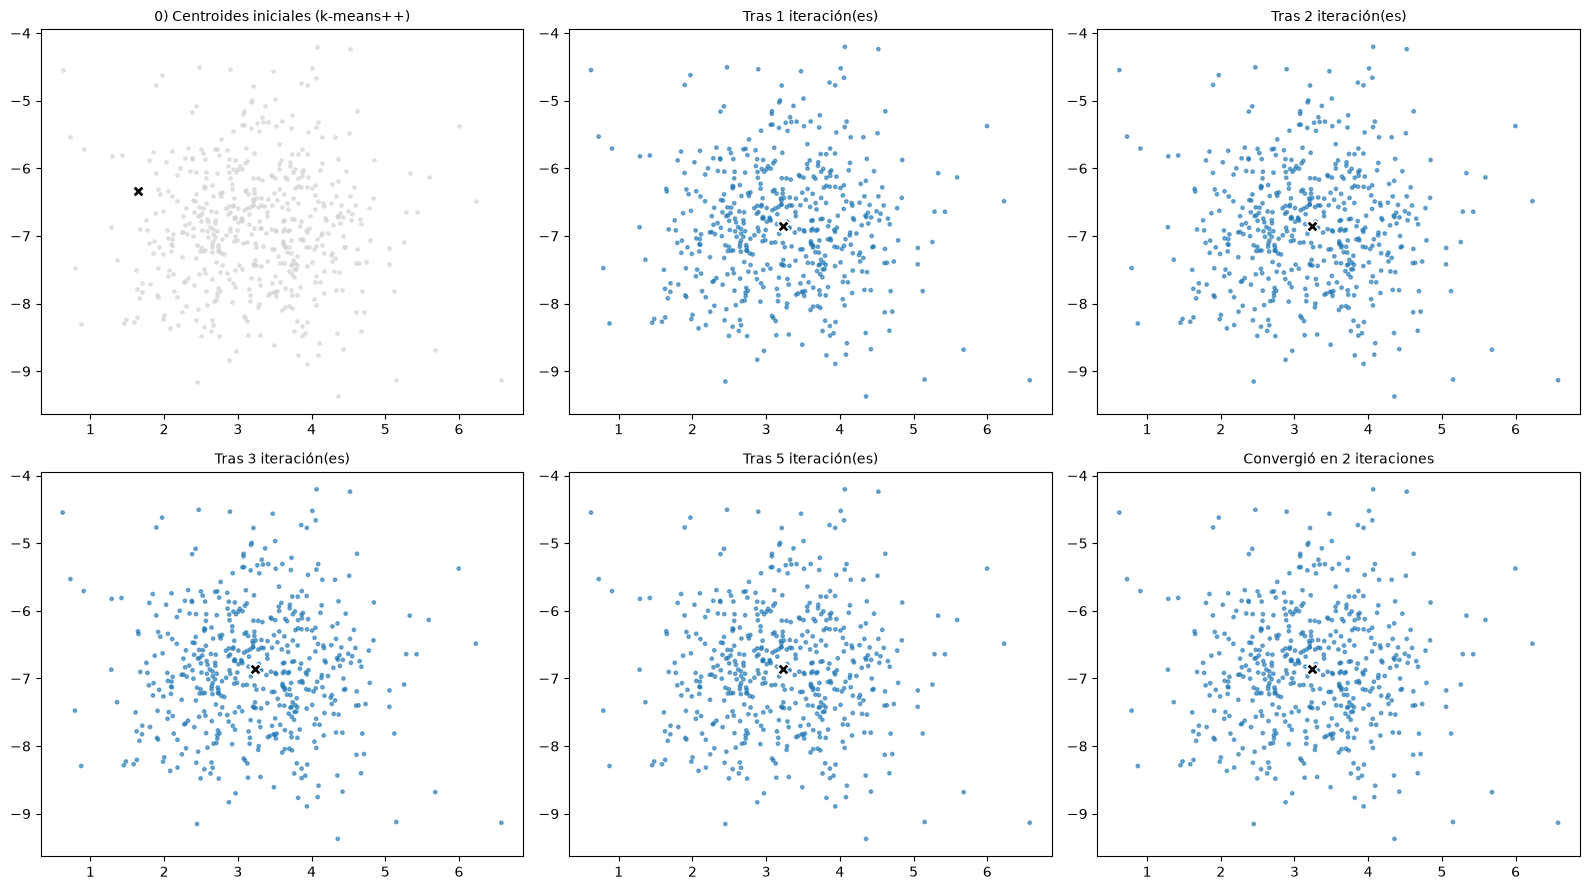


Error centroides hallados vs reales:
  cluster 0: 0.036


,cluster,n_puntos,centroide,idx_5_cercanos
0,0,512,"[3.23, -6.86]","[472, 4, 341, 264, 153]"


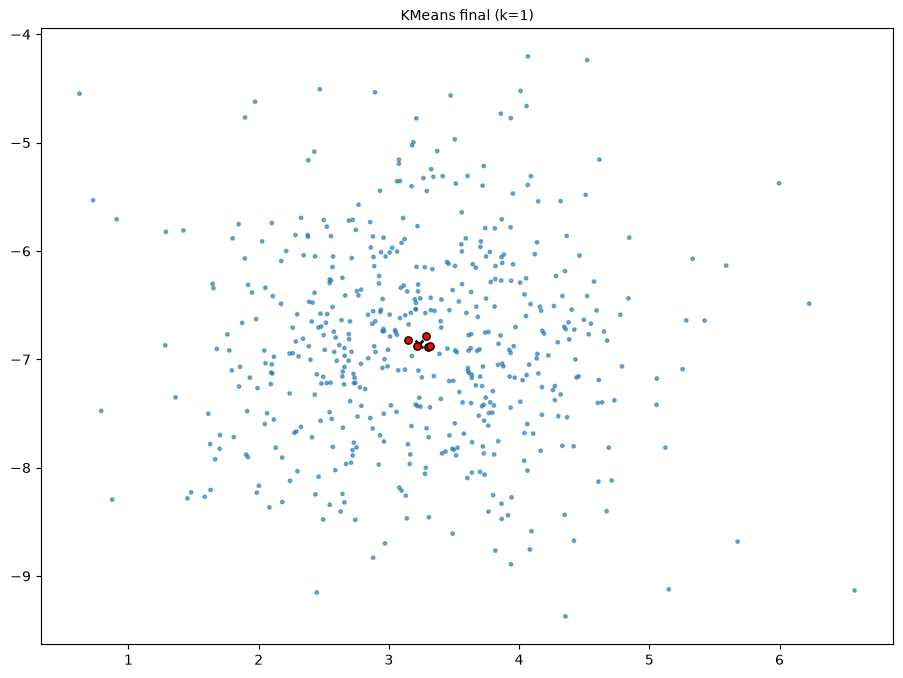

In [31]:
X2, y2, centros2, modelo2 = experimento(dim=2)

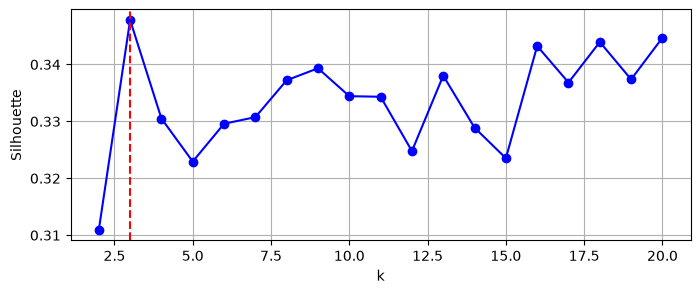

Silhouette sugiere k = 3 | centroides reales = 1


In [32]:
def estimar_k_por_silueta(X, k_max=20):
    ks, sc = range(2, k_max+1), []
    for k in ks:
        m = KMeans(n_clusters=k, n_init=5, random_state=0).fit(X)
        sc.append(silhouette_score(X, m.labels_, sample_size=min(3000,len(X))))
    return ks[np.argmax(sc)], list(ks), sc

k_est, ks, sc = estimar_k_por_silueta(X2)
plt.figure(figsize=(8,3))
plt.plot(ks, sc, "bo-"); plt.axvline(k_est, color="r", ls="--")
plt.xlabel("k"); plt.ylabel("Silhouette"); plt.grid(True); plt.show()
print(f"Silhouette sugiere k = {k_est} | centroides reales = {len(centros2)}")

Centroides: 13 | puntos: 3615 | dim: 3
Puntos por centroide (real): [237, 233, 125, 258, 123, 224, 239, 311, 329, 417, 196, 436, 487]
Std por centroide: [0.53, 1.07, 0.57, 0.85, 0.71, 0.55, 0.65, 1.1, 0.6, 0.82, 0.89, 0.76, 0.5]


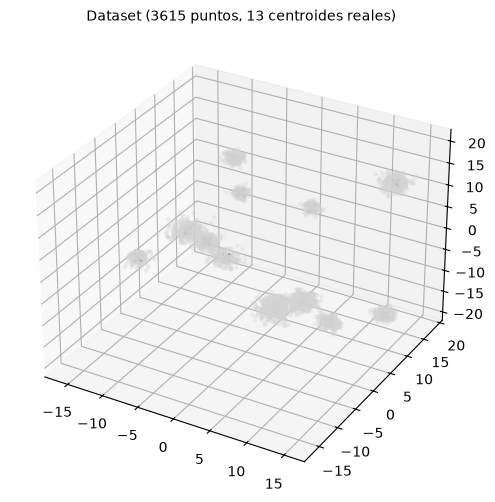

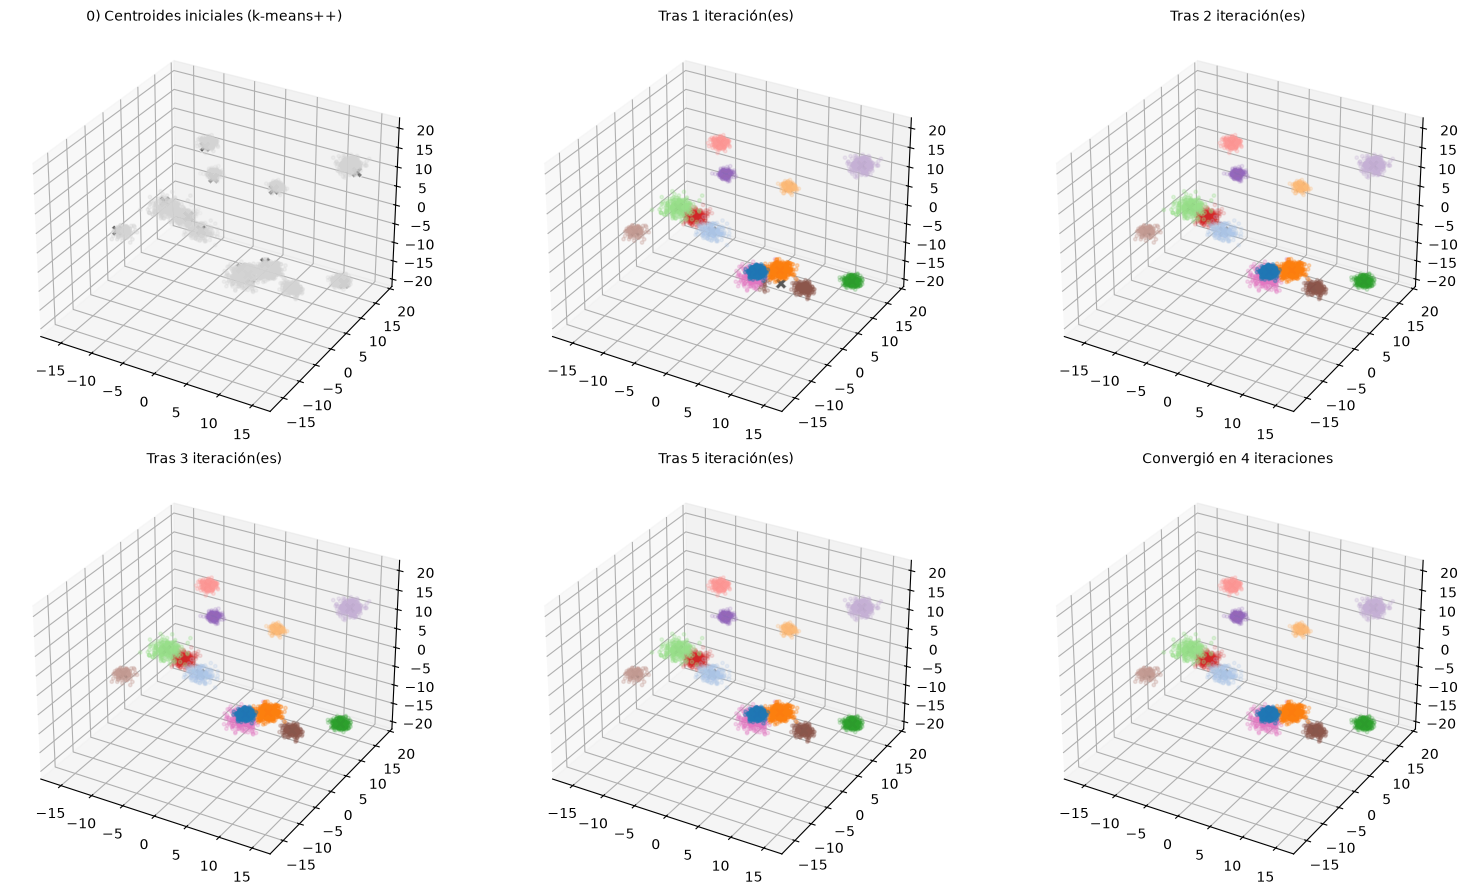


Error centroides hallados vs reales:
  cluster 0: 0.019
  cluster 1: 0.136
  cluster 2: 0.084
  cluster 3: 0.048
  cluster 4: 0.060
  cluster 5: 0.091
  cluster 6: 0.050
  cluster 7: 0.047
  cluster 8: 0.068
  cluster 9: 0.162
  cluster 10: 0.074
  cluster 11: 0.064
  cluster 12: 0.048


,cluster,n_puntos,centroide,idx_5_cercanos
0,0,487,"[11.84, -14.89, 7.03]","[1095, 1614, 1571, 748, 768]"
1,1,196,"[-4.62, 3.18, -4.49]","[3277, 1051, 1451, 3142, 2744]"
2,2,417,"[9.47, -3.36, -2.76]","[2306, 39, 2276, 3568, 1309]"
3,3,125,"[4.63, 8.88, 7.33]","[845, 651, 1977, 3574, 3332]"
4,4,329,"[12.65, 13.82, -17.67]","[2284, 1490, 3554, 1191, 850]"
5,5,233,"[-4.88, -6.13, 8.58]","[1871, 3414, 2281, 1135, 2763]"
6,6,436,"[-13.89, 15.4, -13.99]","[3562, 3028, 2120, 2400, 1792]"
7,7,224,"[-3.73, 4.07, 18.28]","[3080, 894, 2128, 1341, 3381]"
8,8,237,"[-9.21, 16.11, -0.62]","[2581, 1607, 278, 1020, 1264]"
9,9,258,"[13.41, 14.0, 13.25]","[2935, 1287, 838, 3561, 2948]"


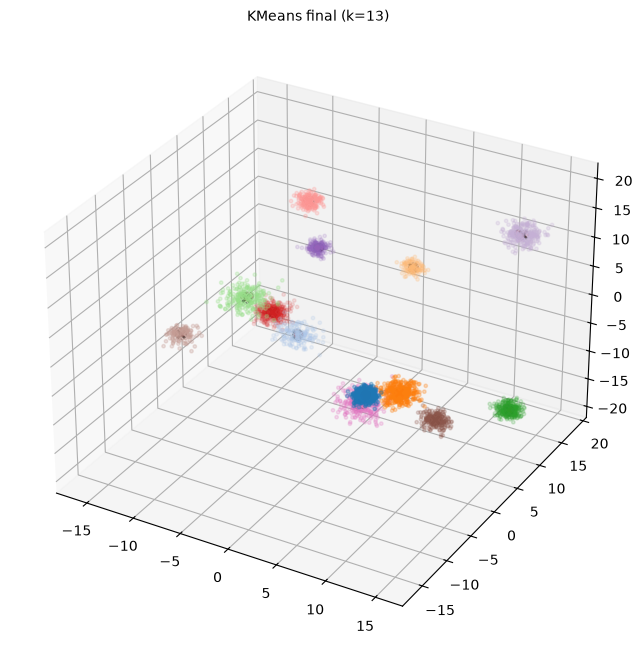

In [33]:
X3, y3, centros3, modelo3 = experimento(dim=3)

In [34]:
!pip install medmnist


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\admin\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [35]:
# pip install medmnist
from medmnist import OrganAMNIST, INFO

train_ds = OrganAMNIST(split="train", size=28, download=True)
test_ds  = OrganAMNIST(split="test", size=28, download=True)

imgs = train_ds.imgs
IMG_SHAPE = imgs.shape[1:]
cmap = "gray" if len(IMG_SHAPE) == 2 else None

X_train = train_ds.imgs.reshape(len(train_ds), -1).astype(np.float32) / 255.0
X_test  = test_ds.imgs.reshape(len(test_ds), -1).astype(np.float32) / 255.0

# Etiquetas reales: reservarlas exclusivamente para evaluación.
y_train_true = train_ds.labels.squeeze().astype(np.int64)
y_test_true  = test_ds.labels.squeeze().astype(np.int64)

m, n = X_train.shape
K = len(INFO["organamnist"]["label"])
print(f"m={m:,} | n={n:,} | K={K}")

# El conjunto de entrenamiento se trata como no etiquetado.
# No usar y_train_true para entrenar KMeans ni asignar pseudoetiquetas.
y_train = np.full(m, -1, dtype=np.int64)

# Reducción de dimensionalidad
pca = PCA(n_components=100, random_state=SEED)
Z_tr = pca.fit_transform(X_train)
Z_te = pca.transform(X_test)

km = MiniBatchKMeans(
    n_clusters=K,
    n_init=10,
    batch_size=1024,
    max_iter=200,
    random_state=SEED
).fit(Z_tr)

dist = km.transform(Z_tr)
idx_rep = np.argmin(dist, axis=0)
X_rep = X_train[idx_rep]

# Solo para evaluación posterior; no usar para entrenar.
y_rep_true = y_train_true[idx_rep]


m=34,561 | n=784 | K=11


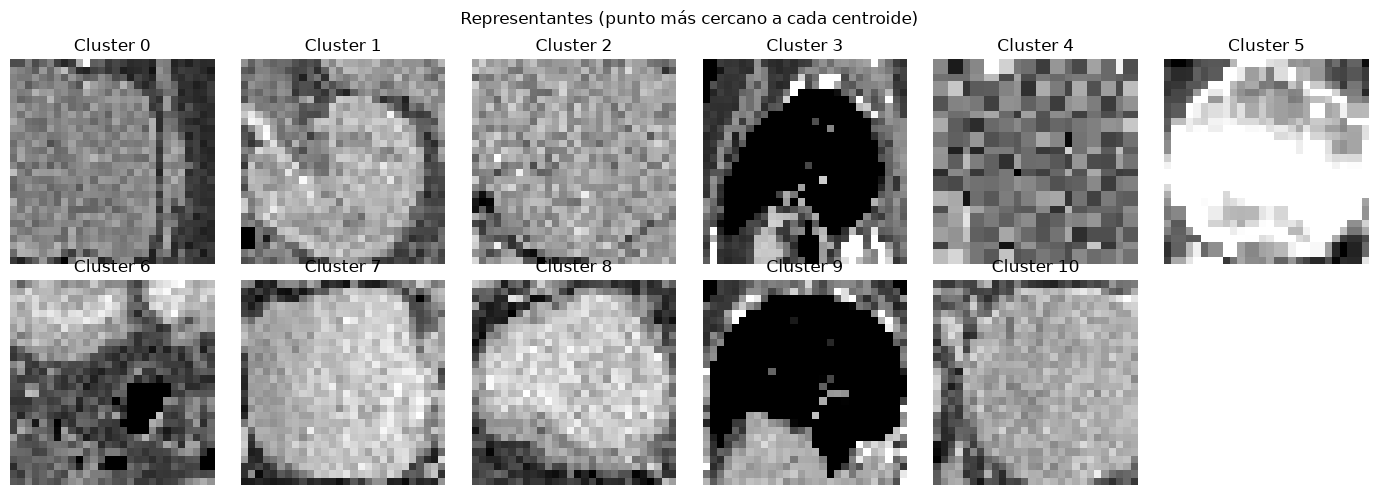

In [36]:
fig, axes = plt.subplots(2, 6, figsize=(14, 5))
axes = axes.ravel()
for i in range(K):
    axes[i].imshow(X_rep[i].reshape(IMG_SHAPE), cmap="gray")
    axes[i].set_title(f"Cluster {i}")
    axes[i].axis("off")
for j in range(K, len(axes)):       # apagar el eje sobrante
    axes[j].axis("off")
plt.suptitle("Representantes (punto más cercano a cada centroide)")
plt.tight_layout()
plt.show()

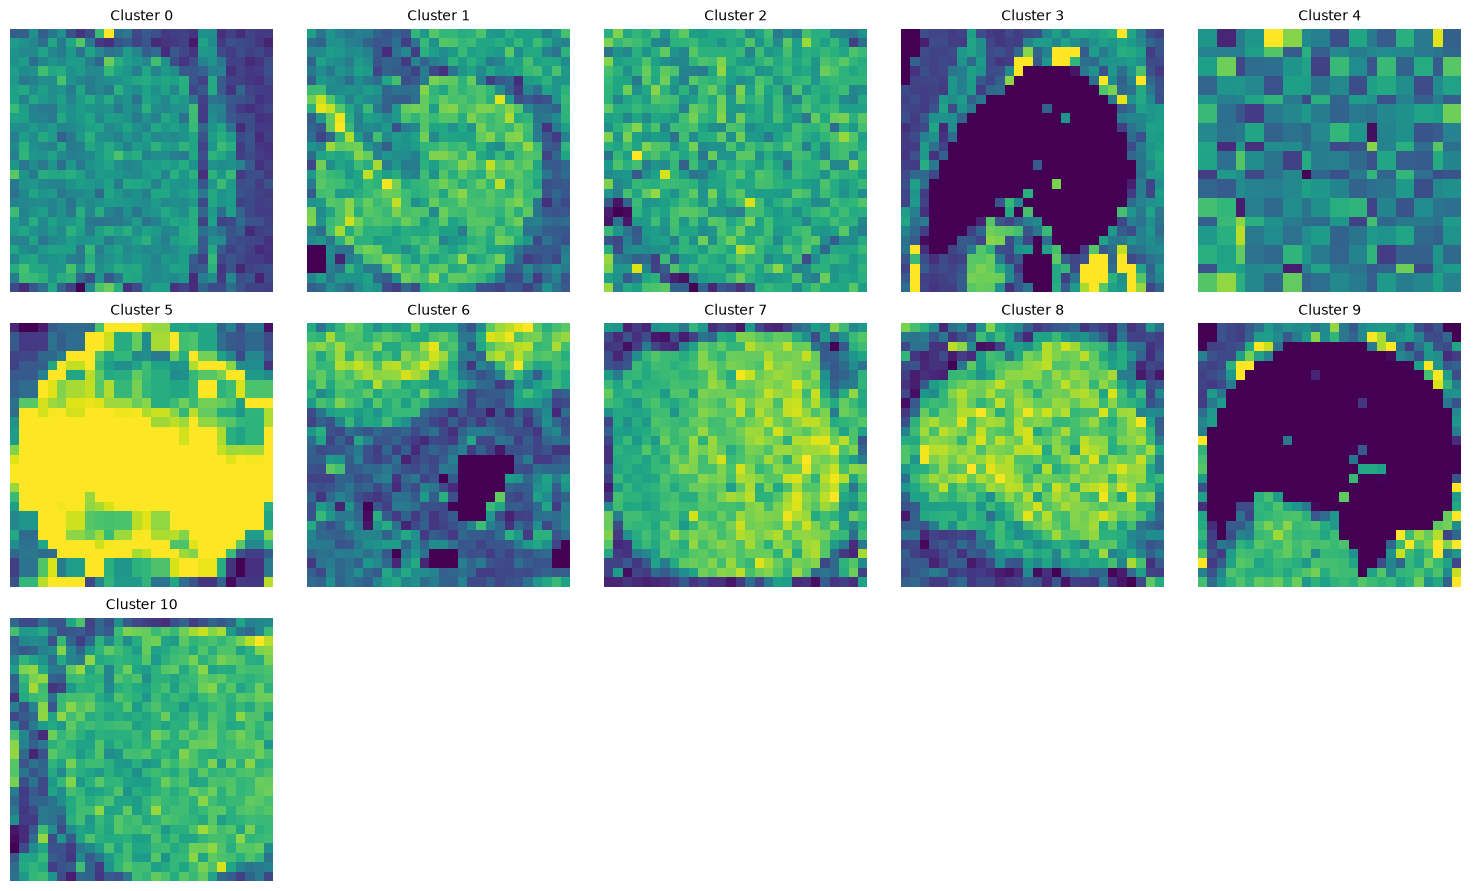

¿Clase del cluster 0? (0-10):  0
¿Clase del cluster 1? (0-10):  1
¿Clase del cluster 2? (0-10):  2
¿Clase del cluster 3? (0-10):  3
¿Clase del cluster 4? (0-10):  4
¿Clase del cluster 5? (0-10):  5
¿Clase del cluster 6? (0-10):  6
¿Clase del cluster 7? (0-10):  7
¿Clase del cluster 8? (0-10):  8
¿Clase del cluster 9? (0-10):  9
¿Clase del cluster 10? (0-10):  10


In [37]:
import math
y_rep = []

ncols = min(K, 5)                    # máximo 5 por fila
nrows = math.ceil(K / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(3*ncols, 3*nrows))
axes = np.atleast_1d(axes).ravel()   # aplanar siempre

for i in range(K):
    axes[i].imshow(X_rep[i].reshape(IMG_SHAPE))
    axes[i].axis("off")
    axes[i].set_title(f"Cluster {i}", fontsize=10)

# apagar ejes sobrantes
for j in range(K, len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

# Inputs después
for i in range(K):
    etiqueta = int(input(f"¿Clase del cluster {i}? (0-{K-1}): "))
    y_rep.append(etiqueta)

y_rep = np.array(y_rep, dtype=np.int64)

In [38]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score

def nuevo_clf():
    return LogisticRegression(max_iter=2000, random_state=SEED)

# Propagar etiqueta del representante a TODO su cluster
y_prop = y_rep[km.labels_]

clf_semi = nuevo_clf().fit(Z_tr, y_prop)

print("Accuracy semi-supervisado:",
      round(accuracy_score(y_test_true, clf_semi.predict(Z_te)), 4))
print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_test_true, clf_semi.predict(Z_te)), 4))

Accuracy semi-supervisado: 0.0408
Balanced Accuracy: 0.0584


In [39]:
# 0) Garantizar consistencia
#y_rep = y_train[idx_rep]          # si no lo era ya
m = Z_tr.shape[0]

# 1) Línea base: solo representantes
clf_base = nuevo_clf().fit(Z_tr[idx_rep], y_rep)

# 2) Pool no etiquetado
pool = np.setdiff1d(np.arange(m), idx_rep)
B = min(200, len(pool))           # <-- fix

# 3) Incertidumbre: menor confianza
probas = clf_base.predict_proba(Z_tr[pool])
confianza = probas.max(axis=1)
orden = np.argsort(confianza)     # ascendente = menos confiado primero
idx_activos = pool[orden[:B]]

# 4) Oráculo
y_activos = 	y_train_true[idx_activos]
clf_activo = nuevo_clf().fit(
    np.vstack([Z_tr[idx_rep], Z_tr[idx_activos]]),
    np.concatenate([y_rep, y_activos])
)

# 5) Azar
rng = np.random.default_rng(SEED)
idx_azar = rng.choice(pool, size=B, replace=False)
clf_azar = nuevo_clf().fit(
    np.vstack([Z_tr[idx_rep], Z_tr[idx_azar]]),
    np.concatenate([y_rep,y_train_true[idx_azar]])
)

# 6) Techo supervisado
clf_full = nuevo_clf().fit(Z_tr, y_train_true)

# 7) EVALUACIÓN 
print("Base(K) :", clf_base.score(Z_te, y_test_true))    
print("Activo  :", clf_activo.score(Z_te, y_test_true))
print("Azar    :", clf_azar.score(Z_te, y_test_true))
print("Full    :", clf_full.score(Z_te, y_test_true))

Base(K) : 0.041174485318933515
Activo  : 0.23399707503656203
Azar    : 0.49465631679604005
Full    : 0.6374732815839802


,Modelo,Etiquetas usadas,Accuracy,Bal. Accuracy
0,Solo representantes,11,0.0412,0.0563
1,Semi-supervisado (prop.),34561,0.0408,0.0584
2,Activo ALEATORIO,211,0.4947,0.4597
3,Activo INCERTIDUMBRE,211,0.2340,0.1918
4,Supervisado completo,34561,0.6375,0.6113


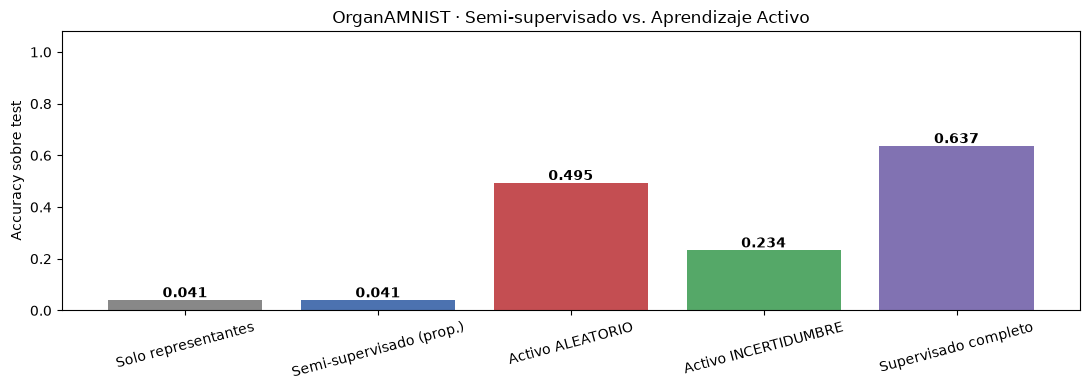

In [40]:
import pandas as pd

filas = [
    ("Solo representantes",       K,     clf_base),
    ("Semi-supervisado (prop.)",  m,     clf_semi),
    ("Activo ALEATORIO",          K+B,   clf_azar),
    ("Activo INCERTIDUMBRE",      K+B,   clf_activo),
    ("Supervisado completo",      m,     clf_full),
]

resumen = pd.DataFrame([{
    "Modelo": n,
    "Etiquetas usadas": e,
    "Accuracy": round(accuracy_score(y_test_true, c.predict(Z_te)), 4),
    "Bal. Accuracy": round(balanced_accuracy_score(y_test_true, c.predict(Z_te)), 4),
} for n, e, c in filas])

display(resumen)

# Gráfica de barras
plt.figure(figsize=(11, 4))
colores = ["#888", "#4c72b0", "#c44e52", "#55a868", "#8172b2"]
plt.bar(resumen["Modelo"], resumen["Accuracy"], color=colores)
for i, v in enumerate(resumen["Accuracy"]):
    plt.text(i, v + 0.01, f"{v:.3f}", ha="center", fontweight="bold")
plt.ylim(0, 1.08)
plt.ylabel("Accuracy sobre test")
plt.title("OrganAMNIST · Semi-supervisado vs. Aprendizaje Activo")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

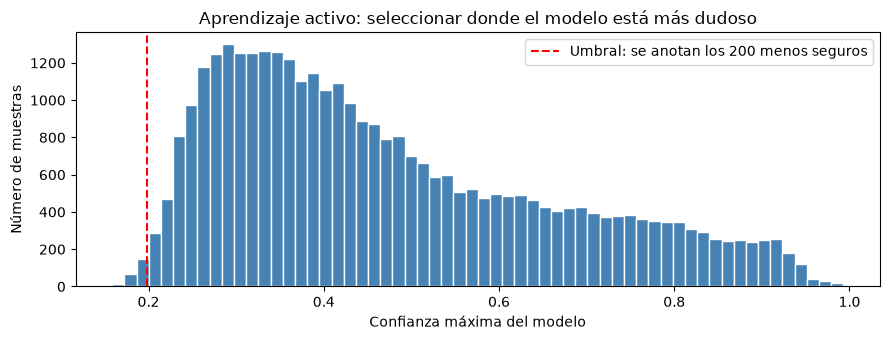

In [41]:
plt.figure(figsize=(9, 3.5))
plt.hist(confianza, bins=60, color="steelblue", edgecolor="white")
plt.axvline(confianza[orden[B-1]], color="red", linestyle="--",
            label=f"Umbral: se anotan los {B} menos seguros")
plt.xlabel("Confianza máxima del modelo")
plt.ylabel("Número de muestras")
plt.title("Aprendizaje activo: seleccionar donde el modelo está más dudoso")
plt.legend()
plt.tight_layout()
plt.show()

📊 Silhouette score: 0.0897


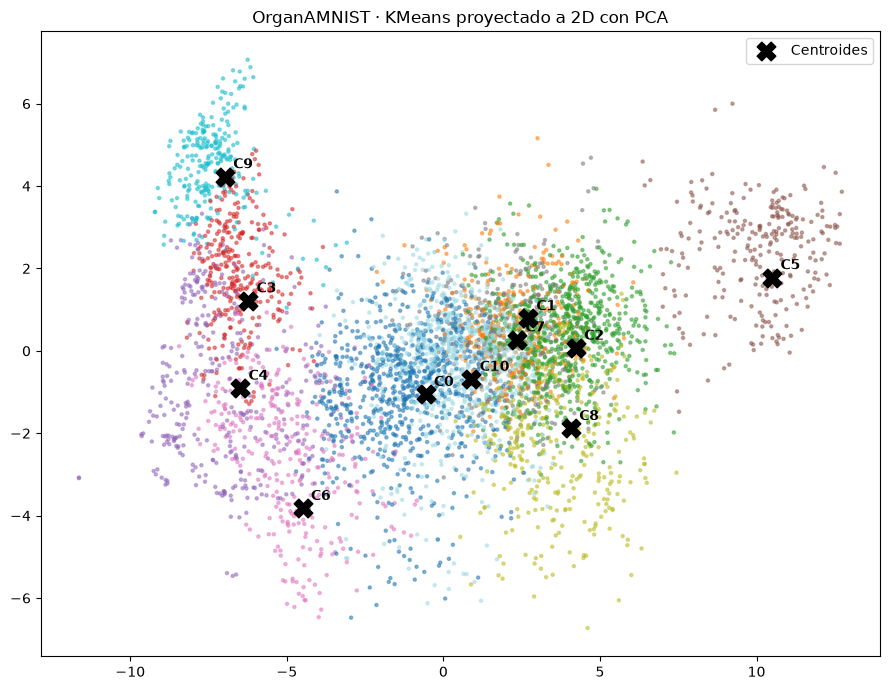

In [42]:
from sklearn.metrics import silhouette_score

idx = rng.choice(m, size=5000, replace=False)
print("📊 Silhouette score:", round(silhouette_score(Z_tr[idx], km.labels_[idx]), 4))

# Visualización 2D de los clusters
Z2 = PCA(n_components=2, random_state=SEED).fit_transform(Z_tr[idx])
centros_2d = PCA(n_components=2, random_state=SEED).fit(km.cluster_centers_).transform(km.cluster_centers_)

plt.figure(figsize=(9, 7))
plt.scatter(Z2[:, 0], Z2[:, 1], c=km.labels_[idx], cmap="tab20", s=5, alpha=0.5)
plt.scatter(centros_2d[:, 0], centros_2d[:, 1], c="black", marker="X", s=180, label="Centroides")
for i, (x, y) in enumerate(centros_2d):
    plt.annotate(f"C{i}", (x, y), xytext=(6, 6), textcoords="offset points", fontweight="bold")
plt.legend()
plt.title("OrganAMNIST · KMeans proyectado a 2D con PCA")
plt.tight_layout()
plt.show()

In [ ]:
%pip install seaborn

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

cm = confusion_matrix(y_test_true, clf_activo.predict(Z_te))
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Matriz de confusión · Aprendizaje Activo")
plt.ylabel("Real"); plt.xlabel("Predicho")
plt.tight_layout()
plt.show()

print(classification_report(y_test_true, clf_activo.predict(Z_te), zero_division=0))